I0000 00:00:1795219809.622803     437 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795219809.653283     437 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795219810.702321     437 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


Predicted Class: Cat
Probability: 1.0000


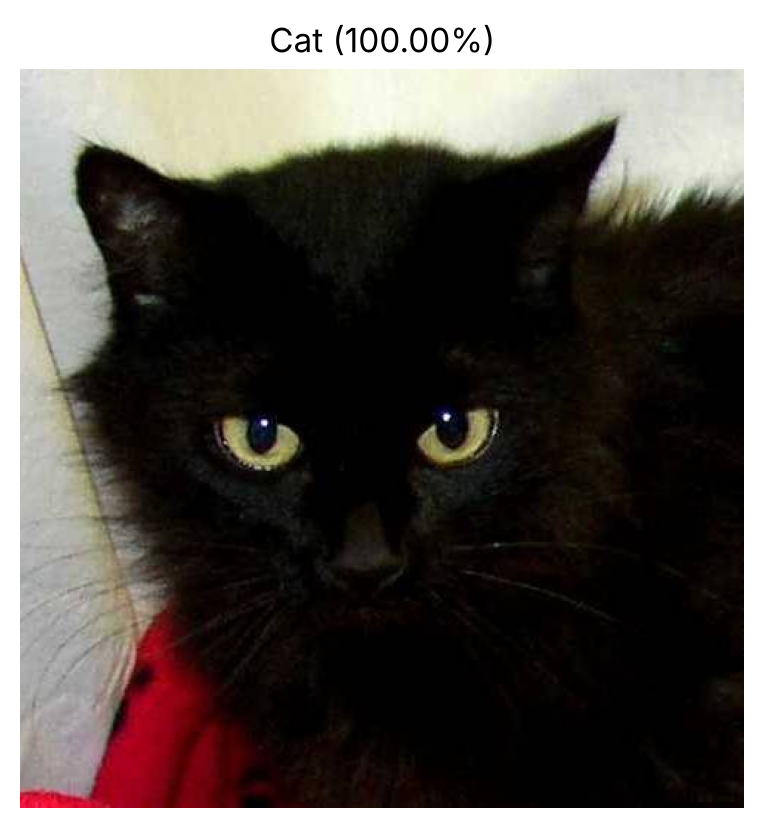

In [1]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

path = 'predict'
model_save_path = 'model_trained_data.h5'
class_labels = {0: 'Cat', 1: 'Dog'}

# 모델 로드 (compile=False로 무거운 경고 코드 방지)
model = tf.keras.models.load_model(model_save_path, compile=False)

def test_image(img_name):
    # 1. 이미지 로드 및 전처리
    img_path = os.path.join(path, img_name)
    original_img = cv2.imread(img_path) # BGR 상태 유지
    
    if original_img is None:
        print(f"이미지를 찾을 수 없습니다: {img_path}")
        return
        
    # [중요] 학습 데이터와 똑같이 BGR 상태에서 리사이즈 및 정규화 진행!
    resized_img = cv2.resize(original_img, (128, 128)) / 255.0
    input_data = resized_img.reshape(1, 128, 128, 3) 

    # 2. 예측 및 결과 해석
    predictions = model.predict(input_data)
    raw_probability = predictions[0][0] 

    if raw_probability > 0.5:
        class_index = 1  # Dog
        probability = raw_probability  
    else:
        class_index = 0  # Cat
        probability = 1.0 - raw_probability  

    # 3. 결과 출력
    print(f"Predicted Class: {class_labels.get(class_index)}")
    print(f"Probability: {probability:.4f}")

    # 화면에 보여줄 때만 사람이 보기 편하게 RGB로 변환
    display_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    plt.imshow(display_img)
    plt.title(f"{class_labels.get(class_index)} ({probability:.2%})")
    plt.axis('off')
    plt.show()

# 테스트 실행
test_image('0-30.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


Predicted Class: Dog
Probability: 1.0000


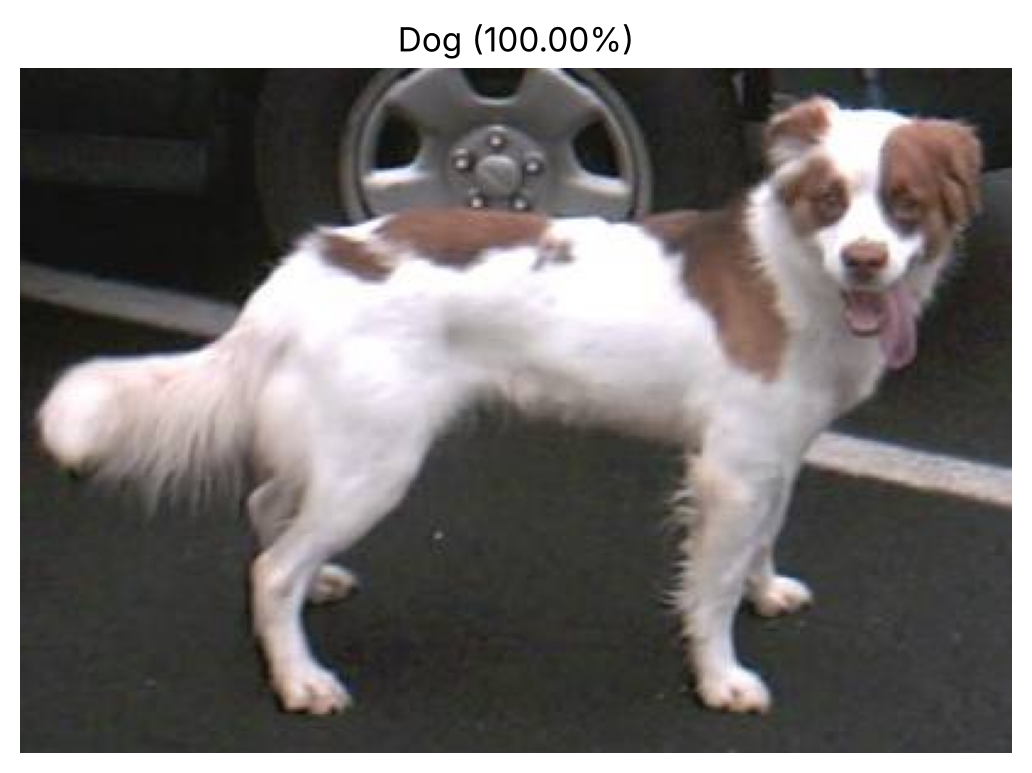

In [2]:
test_image('1-30.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


Predicted Class: Cat
Probability: 0.9900


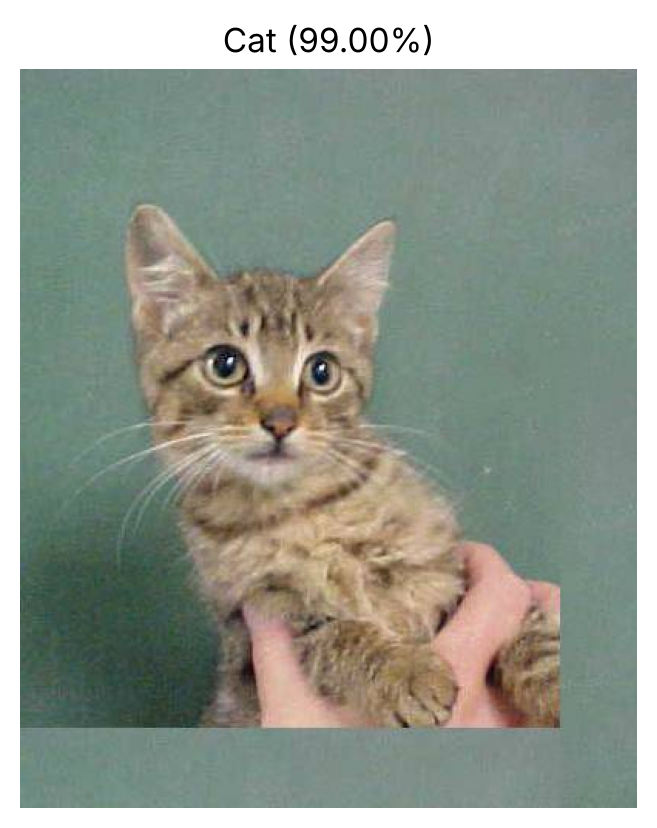

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


Predicted Class: Cat
Probability: 0.9964


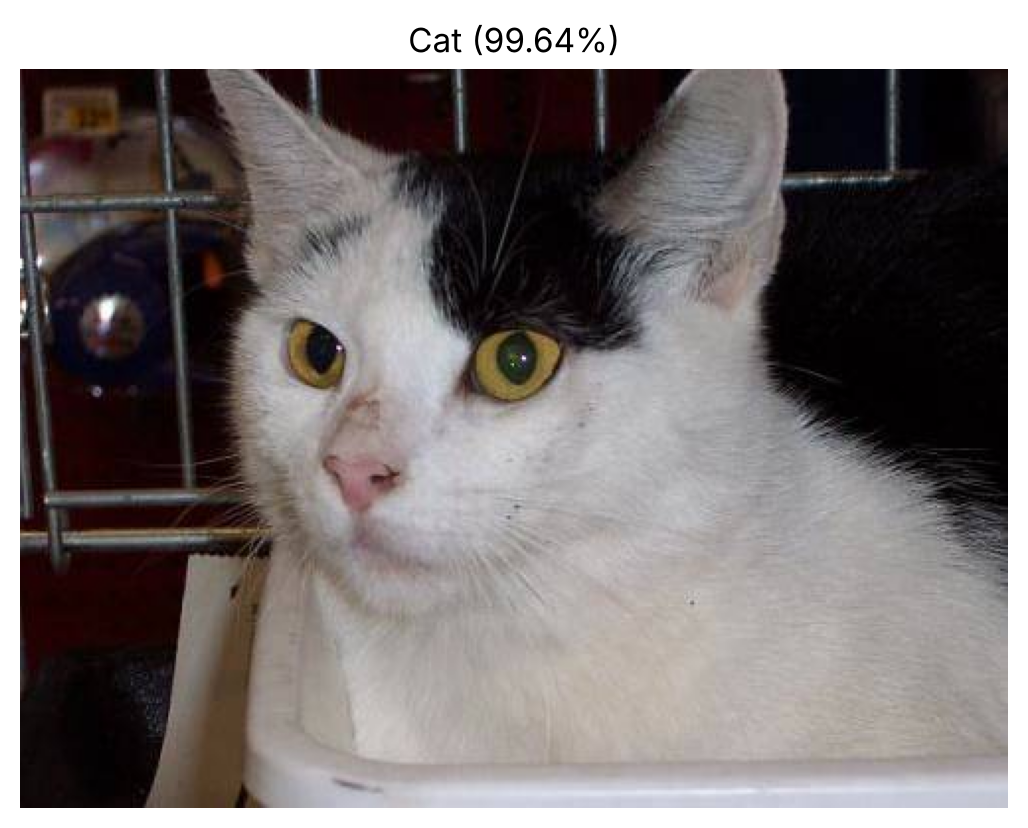

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


Predicted Class: Cat
Probability: 1.0000


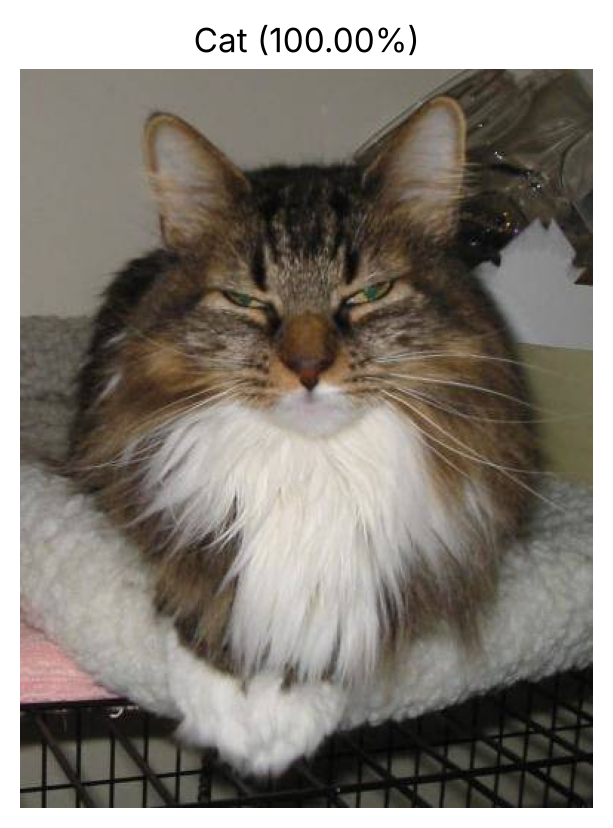

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


Predicted Class: Cat
Probability: 0.8960


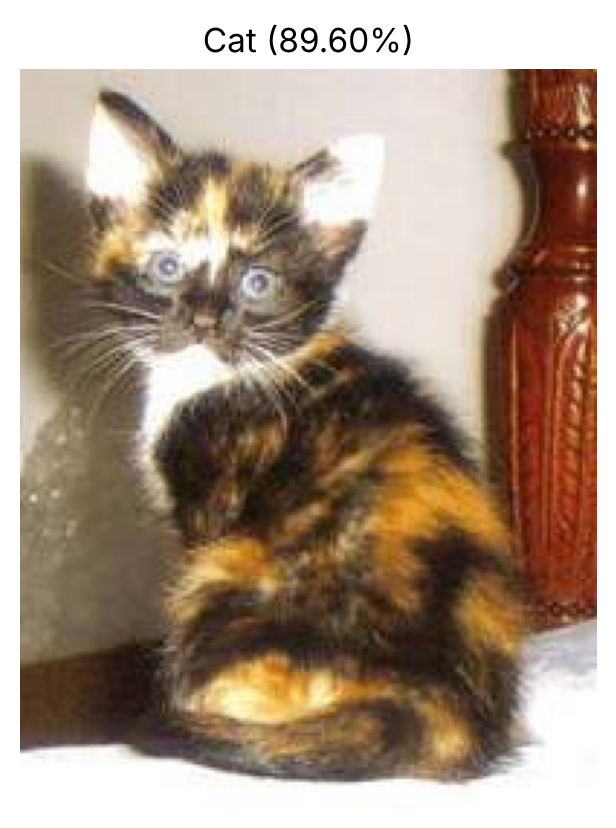

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


Predicted Class: Cat
Probability: 0.9968


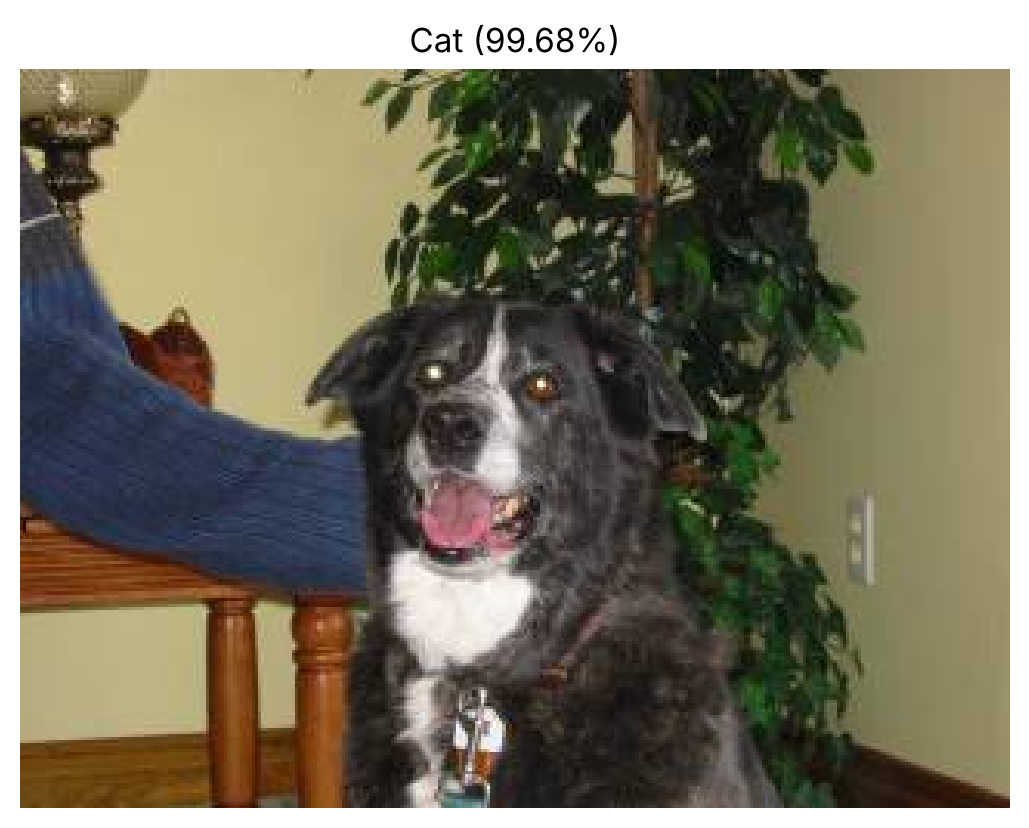

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


Predicted Class: Cat
Probability: 0.9887


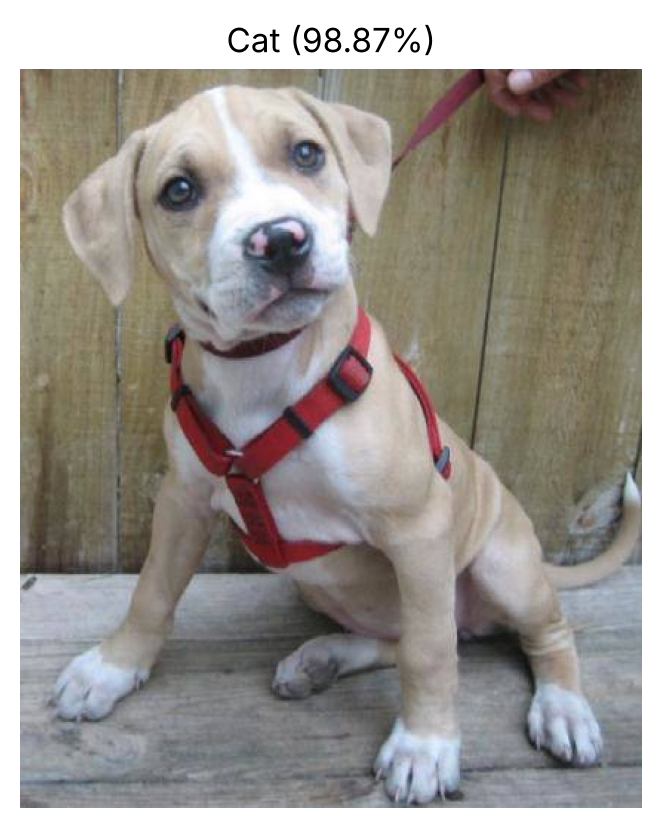

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


Predicted Class: Dog
Probability: 0.9195


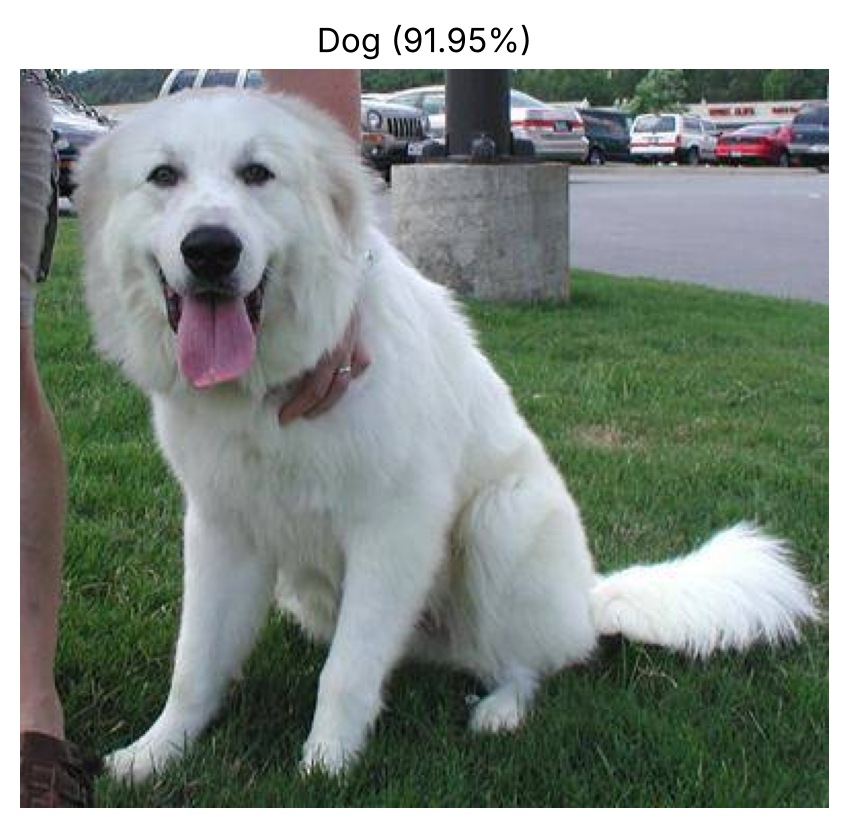

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


Predicted Class: Cat
Probability: 0.9638


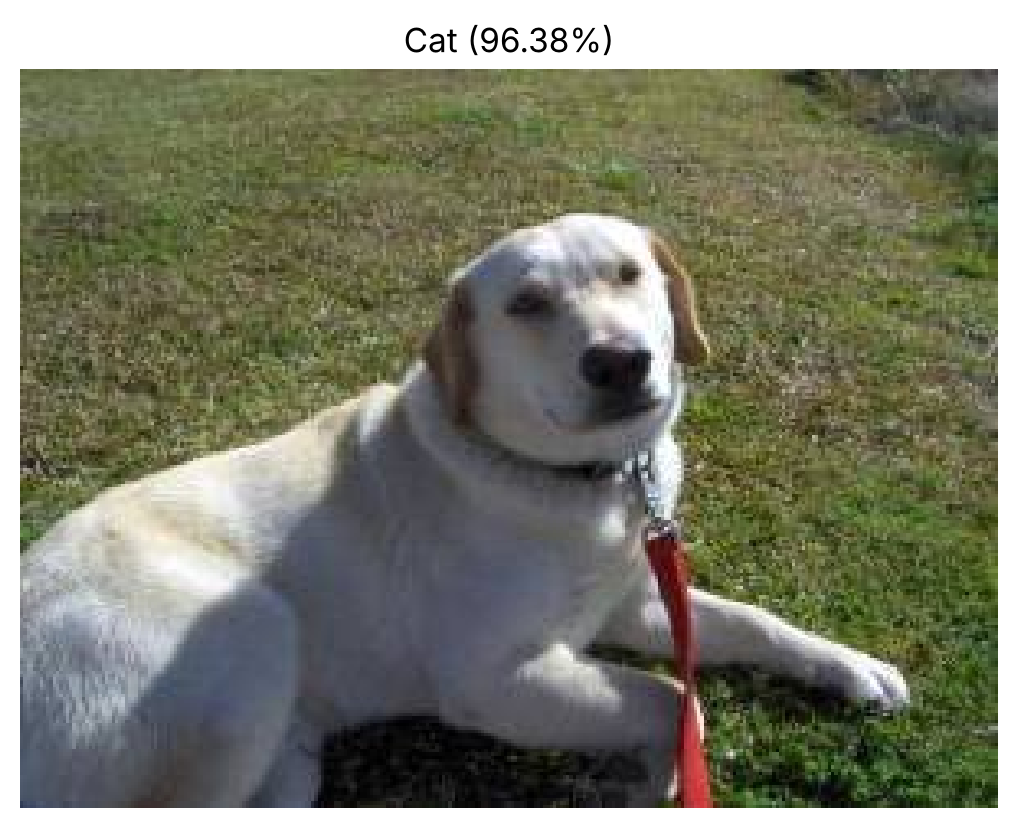

In [3]:
test_image('0-32.jpg')
test_image('0-33.jpg')
test_image('0-34.jpg')
test_image('0-35.jpg')
test_image('1-32.jpg')
test_image('1-33.jpg')
test_image('1-34.jpg')
test_image('1-35.jpg')